# Encoder Layer

Como compreendemos o mecanismo de attenção e como separar diferentes heads pode melhorar a representação dos nossos dados de entrada. Podemos estudar como os componentes são organizados dentro de uma Encoder Layer.

Seguindo a arquitetura proposta pelo artigo original, o encoder é dividido em 2 subcamadas principais:
- Multi-Head Self-Attention
- FFN -> Position Wise Feed Forward Network

Além disso, após cada subcamada temos tanto um *(Residual Conection)* quanto *(Layer Normalization)*. Vamos entender um pouco melhor cada um desses componentes.

## 1. Componentes da Encoder Layer

#### 1.1. Multi-Head Self-Attention

O primeiro componente do Encoder é justamente o MHA que estudamos no notebook anterior. 

Para relembrar rápidamente, o objetivo é permitir que cada token da sequência considere informações provenientes dos demais tokens, produzindo representações contextualizadas.
Uma característica do MHA no Encoder característica que devemos dar foco é a ausência da **Máscara Causal**. Pois nesse ponto, como ainda não estamos fazendo as previsões, não precisamos mascarar os tokens futuros. 

#### 1.2. Add & Norm

Como dissemos anteriormente, após o Multi-Head Attention e o Position Wise Feed Forward Network aplicamos o *Residual Connection* e o *Layer Normalization*. 

Mas afinal, o que é cada um? 

##### **Residual Connection**:

A ideia da conexão residual é bastante simples: em vez de utilizar apenas a transformação produzida pela camada, adicionamos também a representação original que entrou nela.

$$
\operatorname{Residual}(x)=x+\operatorname{Sublayer}(x)
$$
<br>

> "Essa operação cria um caminho direto para a propagação dos gradientes durante o backprop, facilitando o treinamento de redes profundas e ajudando a reduzir os problemas associados ao Vanishing Gradient."

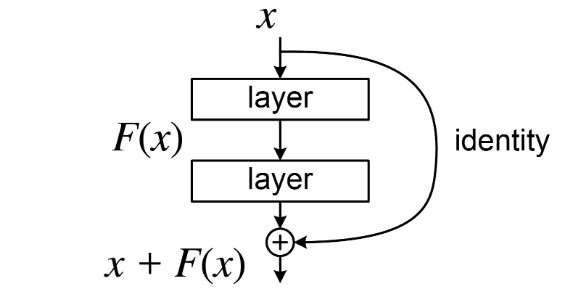

Só um detalhe, utilizamos regra da cadeia durante a backprop, temos o seguinte:

$$
F(x)' + x' \rightarrow F(x)' + 1
$$

É justamente esse termo adicional 1 que representa o caminho direto proveniente do Residual Connection.

##### **Layer Normalization**:

Logo após o Residual Connection, aplicamos diretamente a **Layer Normalization** para normalizar as representações.

Assim como o Layer Normalization, também existe o Batch Normalization. A principal diferença entre eles é a dimensão em que a normalização é aplicada. 
Enquanto a Layer Normalization calcula suas estatísticas considerando as linhas, ou seja as características de cada token. A Batch considera as colunas, portanto considera todos os exemplos do Batch.

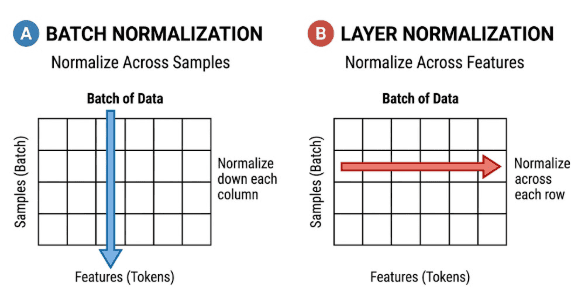

Portanto, considerando a saída do Multi-Head Attention, podemos representar essa etapa segundo o Vaswani et al. (2017):




#### 1.3. Position-Wise Feed-Forward Network (FFN)

Vamos analisar logo de início como se parece a fórmula do FFN e depois vamos destrincha-la:

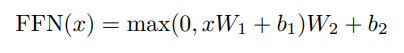

Essa fórmula parece mais complexa do que ela realmente é. Essa formula não é nada mais que 2 camadas lineares com uma função de ativação ReLU entre elas:

```python
nn.Linear(d_model, d_ff), 
nn.ReLU(),
nn.Linear(d_ff, d_model) 

#d_model -> dimensão original
#d_ff    -> dimensão ampliada
```
<br>

Um detalhe é que diferentemente do mecanismo de atenção, a FFN não estabelece relações entre diferentes posições da sequência.

- **Não-Linearidade**: A primeira camada amplia o input para mais dimensões, permitindo com que a rede aprenda relações mais complexas entre dados. E depois segue para a **função de ativação** que introduz uma não linearidade para capturar essas relações. 

*obs: (caso você não saiba o que é introduzir uma não linearidade, pare agora e pesquise. Caso mesmo assim não entenda, busque entender camadas Lineares/Fully-Connected Layers)*

- **Redução de Dimensionalidade**: A segunda camada projeta novamente os dados para o número de dimensões originais, fazendo com que o número de dimensões seja compativel com a proxima camada.

#### 2. Visão Geral

Em resumo, o Encoder pode ser resumido ao seguinte:

1. Multi-Head Attention:
2. Position-Wise Feed-Forward Network:

Onde cada uma dessas subcamadas é sucedida por sua própria *(Residual Conection)* e *(Layer Normalization)*.

**Um último detalhe fundamental:** Geralmente utilizamos multiplas camadas de Encoder, pois apenas uma camada pode não ser suficiente para aprender representações suficientemente complexas da sequência de entrada. O paper original utiliza 6 camadas no Encoder e 6 no Decoder.

In [1]:
from pathlib import Path
import sys

path = Path().resolve().parents[1]

if str(path) not in sys.path:
    sys.path.append(str(path))

In [2]:
import torch.nn as nn
import torch
from src.model import MultiHeadAttention

## Implementação do Position-wise Feed-Forward Networks

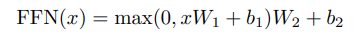

In [3]:
class PositionWiseFFN(nn.Module):
    def __init__(
        self,
        d_model: int,
        d_ff: int,
        dropout
    ):
        
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.model(x))


## Implementação Encoder Layer

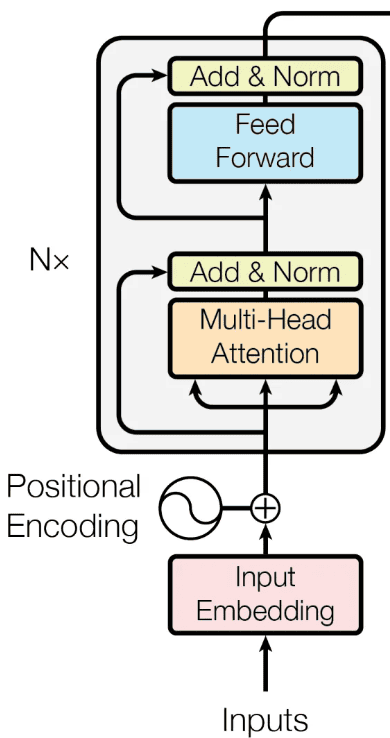
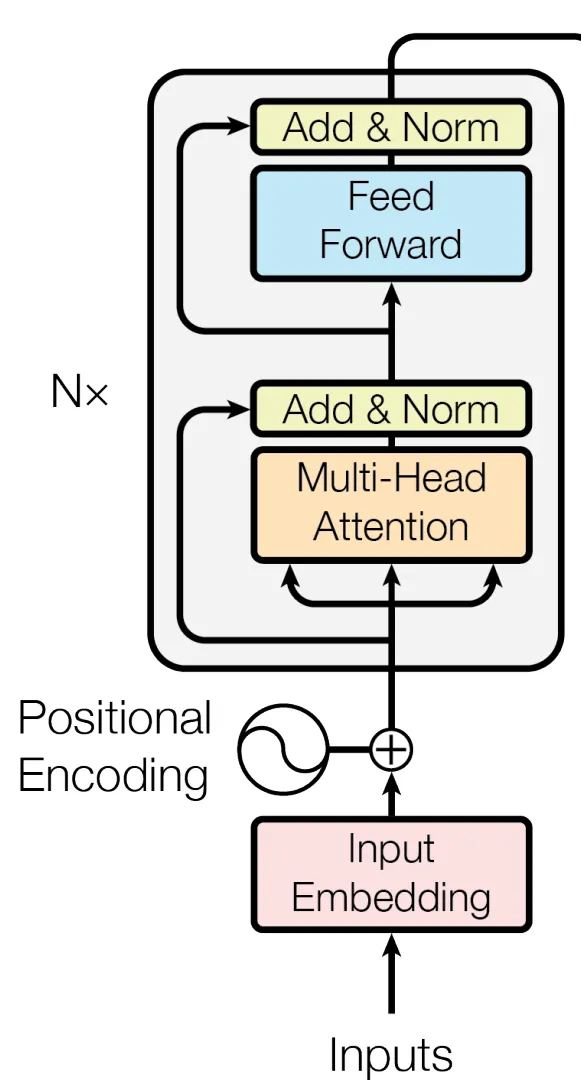

In [ ]:
class EncoderLayer(nn.Module):
    def __init__(
            self,
            d_model: int,        
            d_ff: int,           
            num_heads: int,     
            device: torch.device,
            dropout: float = 0.1 
        ):

        super().__init__()
        self.device = device
        
        self.mha = MultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads,
            device=device,
            dropout=dropout
        )

        self.ffn = PositionWiseFFN(
            d_model=d_model,
            d_ff=d_ff,
            device=device,
            dropout=dropout
        )

        #layer norm
        self.norm_mha = nn.LayerNorm(
            d_model,
            device=device
        )
        
        self.norm_ffn = nn.LayerNorm(
            d_model,
            device=device    
        )

    def forward(
        self,
        x: torch.Tensor,
        attn_mask: torch.Tensor | None = None
    ):

        #Multi-Head Attention + Add & Norm
        mha_output = self.mha(
            query=x,
            key=x,
            value=x,
            attn_mask=attn_mask
        )
        x = self.norm_mha(x + mha_output)

        #Position Wise FFN + Add & Norm
        ffn_output = self.ffn(x)
        x = self.norm_ffn(x + ffn_output)

        return x


# Encoder Completo Com N Camadas

In [5]:
class Encoder(nn.Module):
    def __init__(
        self, 
        d_model:int,          # padrão do paper 512
        d_ff:int,             # padrão do paper 2048
        num_heads:int,        # padrão do paper 8
        num_layers: int = 6,  # padrão do paper 6
        dropout: float = 0.1, # padrão do paper 0.1
        device: torch.device | None = None,
    ):
        
        super().__init__()

        self.layers = nn.ModuleList([
            EncoderLayer(
                d_model=d_model,
                d_ff=d_ff,
                num_heads=num_heads,
                device=device,
                dropout=dropout
            ) for _ in range(num_layers)
        ])

    def forward(
        self,
        x: torch.Tensor,
        attn_mask: torch.Tensor | None = None
    ):

        for layer in self.layers:
            x = layer(
                x,
                attn_mask=attn_mask
            )

        return x